In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/clean/final_df_clean.csv", sep=",")

display(df.head())
print(f"\nThe shape is: {df.shape}")
print(f"\nThe columns are: {df.columns}")

,daytime_evening_attendance,previous_qualification_grade,mothers_qualification,fathers_qualification,mothers_occupation,fathers_occupation,admission_grade,displaced,educational_special_needs,debtor,...,unemployment_rate,inflation_rate,gdp,target,prev_qual_level,application_reordered,application_mode_group,relationship_group,course_name,nationality_group
0,1,122.0,3.0,4.0,services_sellers,unskilled,127.3,1,0,0,...,10.8,1.4,1.74,Dropout,2,5,2nd phase - general contingent,single,Animation and Multimedia Design,Portuguese
1,1,160.0,5.0,7.0,technicians,technicians,142.5,1,0,0,...,13.9,-0.3,0.79,Graduate,2,9,International student (bachelor),single,Tourism,Portuguese
2,1,122.0,1.0,1.0,unskilled,unskilled,124.8,1,0,0,...,10.8,1.4,1.74,Dropout,2,5,1st phase - general contingent,single,Communication Design,Portuguese
3,1,122.0,2.0,1.0,services_sellers,technicians,119.6,1,0,0,...,9.4,-0.8,-3.12,Graduate,2,8,2nd phase - general contingent,single,Journalism and Communication,Portuguese
4,0,100.0,1.0,2.0,unskilled,unskilled,141.5,0,0,0,...,13.9,-0.3,0.79,Graduate,2,9,Over 23 years old,married,Social Service (evening attendance),Portuguese



The shape is: (4424, 37)

The columns are: Index(['daytime_evening_attendance', 'previous_qualification_grade',
       'mothers_qualification', 'fathers_qualification', 'mothers_occupation',
       'fathers_occupation', 'admission_grade', 'displaced',
       'educational_special_needs', 'debtor', 'tuition_fees_up_to_date',
       'gender', 'scholarship_holder', 'age_at_enrollment', 'international',
       'curricular_units_1st_sem_credited',
       'curricular_units_1st_sem_enrolled',
       'curricular_units_1st_sem_evaluations',
       'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade',
       'curricular_units_1st_sem_without_evaluations',
       'curricular_units_2nd_sem_credited',
       'curricular_units_2nd_sem_enrolled',
       'curricular_units_2nd_sem_evaluations',
       'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade',
       'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate',
       'inflation_rate', 'gdp', 'target'

In [2]:
#Check for enrolled students
df["target"].unique()

<StringArray>
['Dropout', 'Graduate', 'Enrolled']
Length: 3, dtype: str

In [3]:
#Save enrolled students for risk prediction
df_enrolled = df[df["target"] == "Enrolled"].copy()

#Exclude enrolled students from training
df = df[df["target"] != "Enrolled"].copy()

In [4]:
df["target"].unique()

<StringArray>
['Dropout', 'Graduate']
Length: 2, dtype: str

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_score, recall_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42

In [6]:
#SPLIT THE DATA FRAME (PLACEHOLDER)
X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=0, stratify=y
)

In [11]:
nominal_features = ['application_mode_group', 'relationship_group', 'course_name', 'nationality_group', 'mothers_occupation', 'fathers_occupation']

ordinal_features = ["application_reordered","mothers_qualification", "fathers_qualification", "prev_qual_level"]

binary_features = ["displaced", "debtor", "tuition_fees_up_to_date", "gender", "scholarship_holder", "international","daytime_evening_attendance","educational_special_needs"]

numerical_features = [
    "admission_grade",
    "previous_qualification_grade",
    "age_at_enrollment",
    "curricular_units_1st_sem_credited",
    "curricular_units_1st_sem_enrolled",
    "curricular_units_1st_sem_evaluations",
    "curricular_units_1st_sem_approved",
    "curricular_units_1st_sem_grade",
    "curricular_units_1st_sem_without_evaluations",
    "curricular_units_2nd_sem_credited",
    "curricular_units_2nd_sem_enrolled",
    "curricular_units_2nd_sem_evaluations",
    "curricular_units_2nd_sem_approved",
    "curricular_units_2nd_sem_grade",
    "curricular_units_2nd_sem_without_evaluations",
    "unemployment_rate",
    "inflation_rate",
    "gdp",
]

## Finding out the features which have high impact on the target
### Chi-square test – Relationship between categorical features and the target
### Inspect mean differences - Relationship between numerical features and the target

In [12]:
from scipy.stats import chi2_contingency

cat_cols = nominal_features + ordinal_features + binary_features

results = []
for column in cat_cols:
    table = pd.crosstab(X_train[column], y_train)
    chi2, p_value, dof, expected = chi2_contingency(table)

    # Cramér's V: strength of the relationship (0 = none, 1 = perfect)
    n = table.to_numpy().sum()
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))

    results.append({
        "feature": column,
        "chi2": round(chi2, 1),
        "p_value": p_value,
        "cramers_v": round(cramers_v, 3),
    })

chi2_results = pd.DataFrame(results).sort_values("cramers_v", ascending=False)
chi2_results

,feature,chi2,p_value,cramers_v
12,tuition_fees_up_to_date,580.4,3.137470e-128,0.447
2,course_name,358.8,1.527502e-66,0.351
0,application_mode_group,305.7,2.524154e-61,0.324
14,scholarship_holder,283.8,1.122880e-63,0.313
11,debtor,215.8,7.348836e-49,0.273
13,gender,195.9,1.609453e-44,0.260
9,prev_qual_level,115.3,3.125549e-23,0.199
4,mothers_occupation,89.3,2.329955e-14,0.175
5,fathers_occupation,74.5,1.667439e-11,0.160
7,mothers_qualification,48.6,2.006521e-07,0.132


### Chi-square results – All categorical and binary features (Graduate vs Dropout)

| Strength | Features (Cramér's V) |
|---|---|
| Strong | Tuition fees up to date (0.45), course (0.35), application mode (0.32), scholarship holder (0.31) |
| Moderate | Debtor (0.27), gender (0.26), previous qualification level (0.20) |
| Weak | Mother's occupation (0.18), father's occupation (0.16), mother's qualification (0.13), father's qualification (0.13), marital status (0.13), displaced (0.12) |
| No relationship (p > 0.05) | Nationality group (p = 0.22), international (p = 0.81) |

Insights:
- Tuition fees up to date is still the strongest feature: students who are behind on fees mostly drop out.
- Course and application mode are strong: dropout depends a lot on which programme students choose and how they were admitted.
- Scholarship holders drop out much less, and debtors drop out much more – financial situation matters.
- Gender has a moderate relationship: men drop out more.
- Family background (parents' occupations and qualifications) is related, but weakly.
- Nationality group and international have no relationship with dropout (p > 0.05),
  and they describe almost the same thing. Both are candidates to drop.

In [13]:
# selecting the features with strong and moderate strength

selected_nominal_features = ['application_mode_group', 'course_name']

selected_ordinal_features = [ "prev_qual_level"]

selected_binary_features = [ "debtor", "tuition_fees_up_to_date", "gender", "scholarship_holder" ]


In [14]:
mean_table = X_train[numerical_features].groupby(y_train).mean().T.round(2)
mean_table

target,Dropout,Graduate
admission_grade,125.02,128.55
previous_qualification_grade,131.14,133.79
age_at_enrollment,26.22,21.72
curricular_units_1st_sem_credited,0.61,0.83
curricular_units_1st_sem_enrolled,5.82,6.66
curricular_units_1st_sem_evaluations,7.77,8.26
curricular_units_1st_sem_approved,2.59,6.23
curricular_units_1st_sem_grade,7.34,12.63
curricular_units_1st_sem_without_evaluations,0.20,0.08
curricular_units_2nd_sem_credited,0.46,0.64


In [15]:
mean_table["mean_difference"]= abs(mean_table["Dropout"] - mean_table["Graduate"])
mean_table.sort_values("mean_difference", key=abs, ascending=False)

target,Dropout,Graduate,mean_difference
curricular_units_2nd_sem_grade,5.97,12.70,6.73
curricular_units_1st_sem_grade,7.34,12.63,5.29
age_at_enrollment,26.22,21.72,4.50
curricular_units_2nd_sem_approved,1.97,6.17,4.20
curricular_units_1st_sem_approved,2.59,6.23,3.64
admission_grade,125.02,128.55,3.53
previous_qualification_grade,131.14,133.79,2.65
curricular_units_2nd_sem_evaluations,7.23,8.16,0.93
curricular_units_1st_sem_enrolled,5.82,6.66,0.84
curricular_units_2nd_sem_enrolled,5.78,6.62,0.84


In [16]:
mean_table["std_difference"] = (mean_table["mean_difference"] / X_train[numerical_features].std()).round(2)
mean_table.sort_values("std_difference", ascending=False)

target,Dropout,Graduate,mean_difference,std_difference
curricular_units_2nd_sem_approved,1.97,6.17,4.20,1.33
curricular_units_2nd_sem_grade,5.97,12.70,6.73,1.23
curricular_units_1st_sem_approved,2.59,6.23,3.64,1.12
curricular_units_1st_sem_grade,7.34,12.63,5.29,1.05
age_at_enrollment,26.22,21.72,4.50,0.57
curricular_units_2nd_sem_enrolled,5.78,6.62,0.84,0.37
curricular_units_1st_sem_enrolled,5.82,6.66,0.84,0.33
admission_grade,125.02,128.55,3.53,0.24
curricular_units_2nd_sem_without_evaluations,0.26,0.08,0.18,0.24
curricular_units_2nd_sem_evaluations,7.23,8.16,0.93,0.24


### Numerical features – Results

- Approved units and grades (both semesters) show the biggest differences:
  dropouts pass far fewer units and have much lower grades. These are the strongest features.
- Age has a medium difference: dropouts are about 4.5 years older on average.
- Admission grade, enrolled units and evaluations show small differences.
- GDP, inflation and unemployment show almost no difference – candidates to drop.

Differences were divided by the standard deviation, so features with different scales can be compared.

In [17]:
# Selecting the features with high to moderate difference in std 

selected_numerical_features = [
    "curricular_units_1st_sem_approved",
    "curricular_units_1st_sem_grade",
    "curricular_units_2nd_sem_approved",
    "curricular_units_2nd_sem_grade",
    "age_at_enrollment", 
    "admission_grade",
    "curricular_units_1st_sem_enrolled",
    "curricular_units_2nd_sem_enrolled"
]
    
# Dropping the below features with almost no difference in std

"curricular_units_1st_sem_credited",
"curricular_units_1st_sem_evaluations",
"curricular_units_1st_sem_without_evaluations",
"curricular_units_2nd_sem_credited",
"curricular_units_2nd_sem_evaluations",
"curricular_units_2nd_sem_without_evaluations",
"unemployment_rate",
"inflation_rate",
"gdp"

'gdp'

## Feature Selection - Correlation Analysis

Pearson correlation is used to investigate relationships
between the selected features and the target variable,
as well as potential redundancy between features.

In [18]:
correlation_matrix = X_train[selected_numerical_features].corr()
correlation_matrix.round(2)

,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,age_at_enrollment,admission_grade,curricular_units_1st_sem_enrolled,curricular_units_2nd_sem_enrolled
curricular_units_1st_sem_approved,1.00,0.71,0.92,0.71,-0.08,0.08,0.78,0.74
curricular_units_1st_sem_grade,0.71,1.00,0.69,0.84,-0.17,0.10,0.38,0.41
curricular_units_2nd_sem_approved,0.92,0.69,1.00,0.78,-0.15,0.08,0.68,0.71
curricular_units_2nd_sem_grade,0.71,0.84,0.78,1.00,-0.20,0.09,0.37,0.41
age_at_enrollment,-0.08,-0.17,-0.15,-0.20,1.00,-0.03,0.13,0.07
admission_grade,0.08,0.10,0.08,0.09,-0.03,1.00,-0.03,-0.05
curricular_units_1st_sem_enrolled,0.78,0.38,0.68,0.37,0.13,-0.03,1.00,0.94
curricular_units_2nd_sem_enrolled,0.74,0.41,0.71,0.41,0.07,-0.05,0.94,1.00


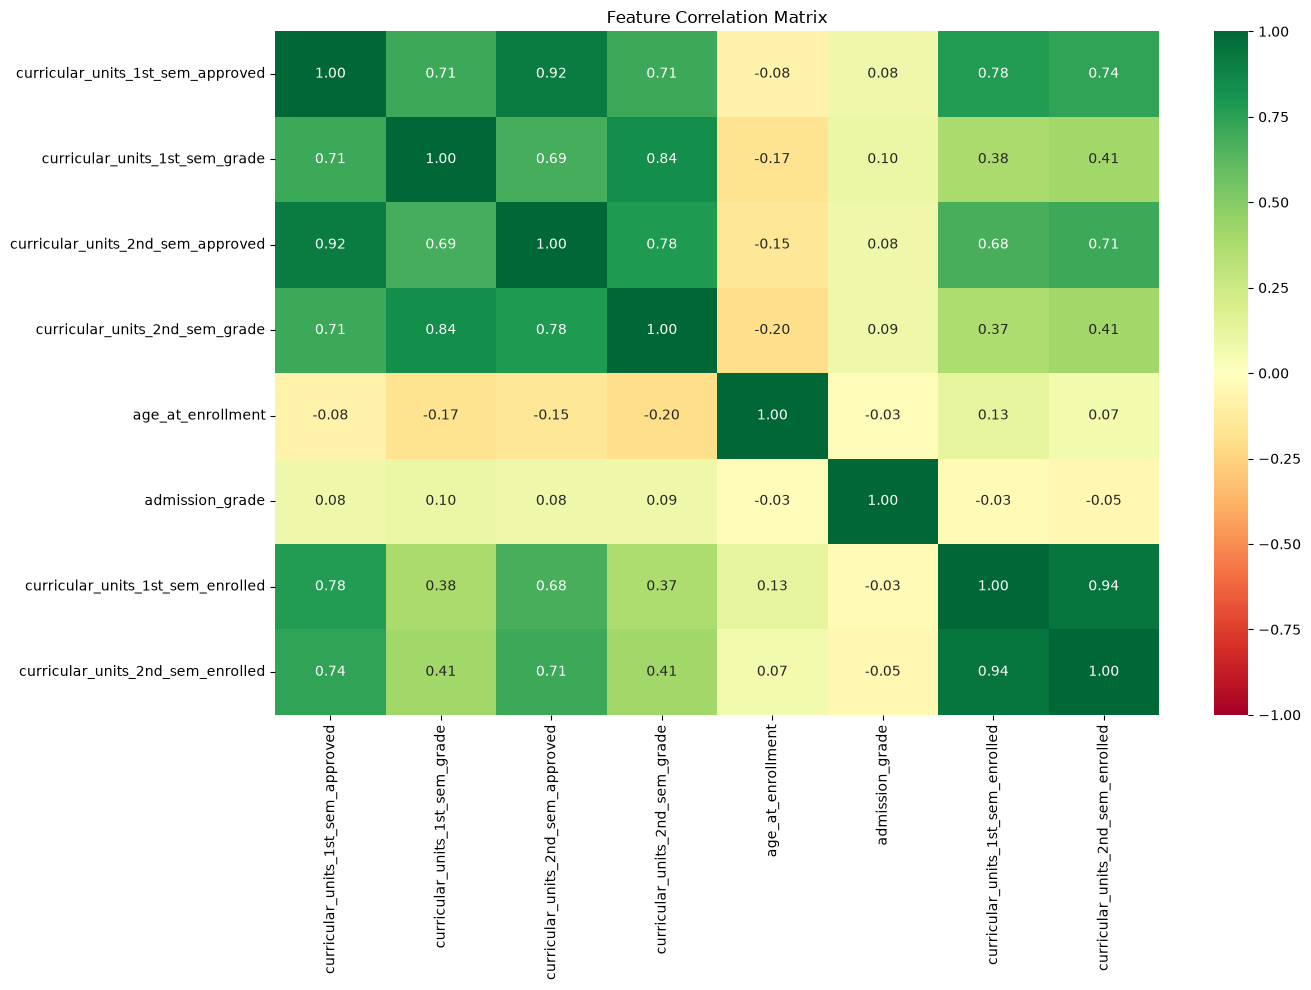

In [19]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

### Removing features which are highly correlated with each other


Highly correlated > 0.9 
"curricular_units_1st_sem_enrolled","curricular_units_2nd_sem_enrolled"
"curricular_units_1st_sem_approved","curricular_units_2nd_sem_approved"

Highly correlated > 0.8
"curricular_units_1st_sem_grade","curricular_units_2nd_sem_grade"

Selecting one from the pair in the above highly correlated features: "curricular_units_2nd_sem_enrolled","curricular_units_2nd_sem_approved",
"curricular_units_2nd_sem_grade"


In [20]:
selected_numerical_features = [
    "curricular_units_2nd_sem_enrolled",
    "curricular_units_2nd_sem_approved",
    "curricular_units_2nd_sem_grade",   
    "age_at_enrollment", 
    "admission_grade"
]
    
# Dropping the below features with almost no difference in std

"curricular_units_1st_sem_credited",
"curricular_units_1st_sem_evaluations",
"curricular_units_1st_sem_without_evaluations",
"curricular_units_2nd_sem_credited",
"curricular_units_2nd_sem_evaluations",
"curricular_units_2nd_sem_without_evaluations",
"unemployment_rate",
"inflation_rate",
"gdp"

'gdp'

In [21]:
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaling", MinMaxScaler()),
])
nominal_pipeline = Pipeline([("encoding", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
numerical_pipeline = Pipeline([("scaling", MinMaxScaler())])

In [22]:
# Preprocessor for column transformation
preprocessor = ColumnTransformer([
    ("ordinal", ordinal_pipeline, selected_ordinal_features),
    ("nominal", nominal_pipeline, selected_nominal_features),
    ("numerical", numerical_pipeline, selected_numerical_features),
    ("binary", "passthrough", selected_binary_features),
])

In [23]:
# Run KNN Model and fit
knn_pipeline = Pipeline([("preprocess", preprocessor),
                         ("model", KNeighborsClassifier(n_neighbors=5))])
knn_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Dropout','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](36,)","['daytime_evening_attendance','previous_qualification_grade', 'mothers_qualification',...,'relationship_group','course_name', 'nationality_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,36
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the n

In [24]:
# Check Training vs Test Accuracy
print("Training accuracy:", round(knn_pipeline.score(X_train, y_train), 3))
print("Test accuracy:", round(knn_pipeline.score(X_test, y_test), 3))

Training accuracy: 0.881
Test accuracy: 0.8


In [25]:
y_pred_train_knn = knn_pipeline.predict(X_train)
y_pred_test_knn  = knn_pipeline.predict(X_test)

comparison_students = pd.DataFrame({
    "actual_student_status": y_test,
    "predicted_student_status": pd.Series(y_pred_test_knn, index=y_test.index),
})

display(comparison_students.head(10))

,actual_student_status,predicted_student_status
3989,Graduate,Graduate
959,Dropout,Dropout
265,Graduate,Graduate
243,Dropout,Dropout
3919,Graduate,Graduate
1531,Graduate,Graduate
144,Graduate,Graduate
1377,Graduate,Graduate
683,Dropout,Dropout
2028,Graduate,Graduate


In [26]:
classification_metrics = pd.DataFrame({
    "Training": {
        "Accuracy": accuracy_score(y_train, y_pred_train_knn),
        "Precision (macro)": precision_score(y_train, y_pred_train_knn, average='macro'),
        "Recall (macro)": recall_score(y_train, y_pred_train_knn, average='macro'),
        "Recall (Dropout)": recall_score(y_train, y_pred_train_knn, pos_label="Dropout"),
    },
    "Test": {
        "Accuracy": accuracy_score(y_test, y_pred_test_knn),
        "Precision (macro)": precision_score(y_test, y_pred_test_knn, average='macro'),
        "Recall (macro)": recall_score(y_test, y_pred_test_knn, average='macro'),
        "Recall (Dropout)": recall_score(y_test, y_pred_test_knn, pos_label="Dropout"),
    },
})
display(classification_metrics.round(3))

,Training,Test
Accuracy,0.881,0.800
Precision (macro),0.890,0.804
Recall (macro),0.860,0.771
Recall (Dropout),0.763,0.634


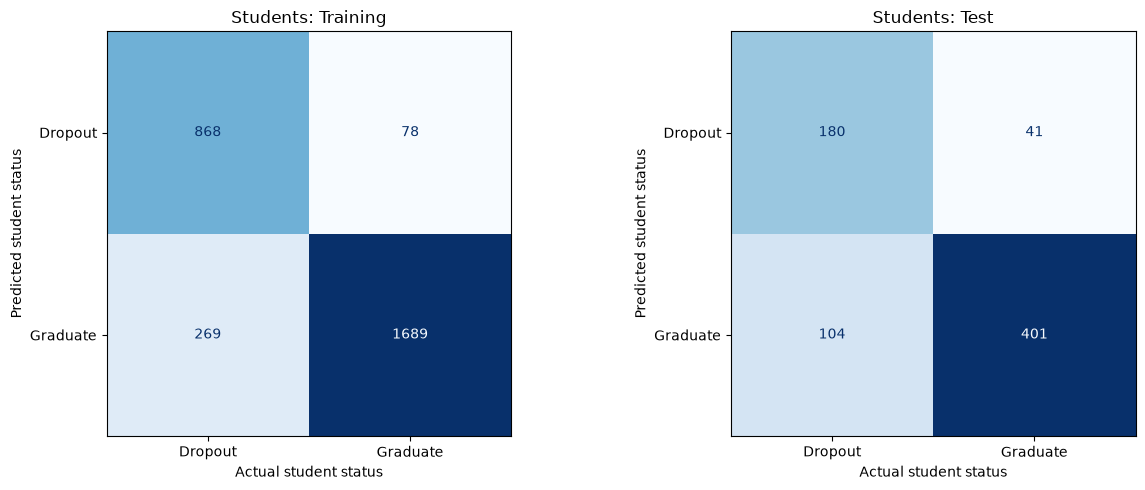

In [27]:
# One class order, used by both the matrix and the labels
class_order = ["Dropout", "Graduate"]

# Compute confusion matrices for both datasets
cm_train = confusion_matrix(y_train, y_pred_train_knn, labels=class_order)
cm_test  = confusion_matrix(y_test,  y_pred_test_knn,  labels=class_order)

# Plot the confusion matrices: train vs test
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cm, split_name in zip(axes, [cm_train, cm_test], ["Training", "Test"]):
    # Transpose: predicted classes on rows, actual classes on columns.
    ConfusionMatrixDisplay(
        confusion_matrix=cm.T,
        display_labels=class_order,
    ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_xlabel("Actual student status")
    ax.set_ylabel("Predicted student status")
    ax.set_title(f"Students: {split_name}")

plt.tight_layout()
plt.show()

### Results: without vs with selected features

| | Without selected features | With selected features |
|---|---|---|
| Train accuracy | 0.85 | 0.88 |
| Test accuracy | 0.77 | 0.83 |
| Dropout recall (test) | 0.57 | 0.67 |
| Dropouts missed | 43% | 33% |

- With selected features, test accuracy improved from 0.77 to 0.83.
- Dropout recall improved from 0.57 to 0.67: the model now finds 2 out of 3 dropouts
  and misses about 1 in 3 (without selection it missed more than 4 in 10).
- Train and test accuracy are closer together with selected features, so the model generalises better.
- Using only the features with a real relationship to the target made the model better
  at finding students at risk.
- We still miss one third of dropouts. Next steps: lower the decision threshold
  and use class weights to catch more of them.

In [28]:
selected_nominal_features = ['application_mode_group', 'course_name']

selected_ordinal_features = [ "prev_qual_level"]

selected_binary_features = [ "debtor", "tuition_fees_up_to_date", "gender", "scholarship_holder" ]

selected_numerical_features = [
    "curricular_units_2nd_sem_enrolled",
    "curricular_units_2nd_sem_approved",
    "curricular_units_2nd_sem_grade",   
    "age_at_enrollment", 
    "admission_grade"
]

In [29]:
selected_features = (
    selected_nominal_features
    + selected_ordinal_features
    + selected_binary_features
    + selected_numerical_features
)

df_selected = df[selected_features + ["target"]].copy()

df_selected.to_csv("../data/clean/selected_features.csv", index=False)